In [1]:
import numpy as np
from base.iterative_section_minimiser import mesh_intersect
from stl import Mesh
import base.geometry as geom
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.neighbors import NearestNeighbors

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
centrespline = np.loadtxt(f"./temp/centrelines/MST_straight_cylinder_L8_R1_stochastic_200_centerspline-direct.txt")
vectors = centrespline[1:] - centrespline[:-1]
norm_vectors = np.linalg.norm(vectors, axis=1)

normed_vectors = vectors / np.expand_dims(norm_vectors, -1)

In [3]:
mesh_data = Mesh.from_file(f"./data/straight_cylinder_L8_R1_stochastic.stl")

In [4]:
sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centrespline[1:-1:5], normed_vectors[::5]))]

28it [00:06,  4.39it/s]


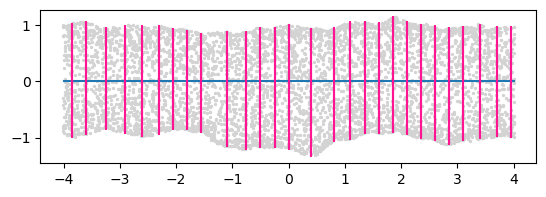

In [5]:
fig, ax = plt.subplots()

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centrespline[:, [0,1]].T)
for section in sections:
    ax.plot(*section[0][:, [0,1]].T, color = "deeppink")

ax.set_aspect("equal")

In [6]:
vertices2d = [geom.to2D(elem[0], elem[5]) for elem in sections]

In [7]:
descriptors = []

for section in vertices2d:
    cog = geom.centre_of_gravity(np.vstack([section.T, np.zeros(len(section))]).T)[:-1]
    area = geom.compute_ngon_area(section)
    perimeter = geom.compute_ngon_perimeter(section)
    max_length = geom.compute_max_pairwise_distance(section)
    rmax = geom.compute_rmax(section, cog)
    rmin = geom.compute_rmin(section, cog)
    r_average = geom.compute_rave(section, cog)
    solidity = geom.compute_polygon_solidity(section)

    determined_ellipse, ellipse_area, ellipse_perimeter, ellipse_aspect_ratio = geom.fit_ellipse(section)

    description = dict(
    cog = cog,
    area = area,
    ellipse_area= ellipse_area,
    ellipse_aspect_ratio = ellipse_aspect_ratio,
    perimeter = perimeter,
    solidity = solidity,
    hydraulic_diameter = geom.compute_ngon_dh(area, perimeter),
    max_length = max_length,
    rmax = rmax,
    rmin = rmin,
    r_average = r_average,
    circularity = rmin / rmax,
    circularity2 = perimeter **2 / area,
    gravelius_compactness = perimeter **2 / (2* np.sqrt(np.pi*area)),
    circularity3 = (rmax - rmin) / rmin,
    deviation_from_inscribe_disk = np.pi * rmin**2 / area,
    deviation_from_circumsribed_disk = np.pi * rmax**2 / area,
    elongation = 4 / np.pi *  (area / r_average**2),
    isoperimetric_deficiency = 4* np.pi * area / perimeter**2,
    morton_spreading_index = 4 / np.pi * (area / max_length**2),
    circular_variance = geom.compute_circular_variance(section, cog, area))

    descriptors.append(description)

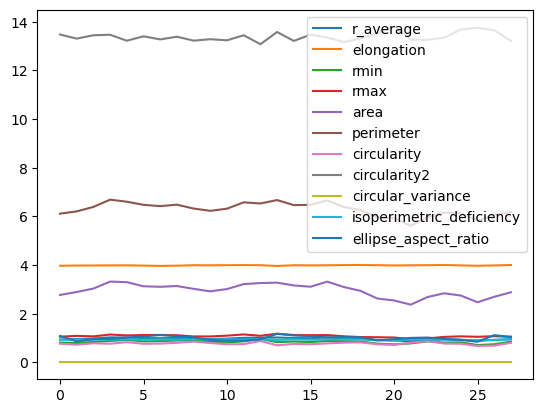

In [8]:
plt.plot([elem["r_average"] for elem in descriptors], label = "r_average")
plt.plot([elem["elongation"] for elem in descriptors], label = "elongation")
plt.plot([elem["rmin"] for elem in descriptors], label = "rmin")
plt.plot([elem["rmax"] for elem in descriptors], label = "rmax")
plt.plot([elem["area"] for elem in descriptors], label = "area")
plt.plot([elem["perimeter"] for elem in descriptors], label = "perimeter")
plt.plot([elem["circularity"] for elem in descriptors], label = "circularity")
plt.plot([elem["circularity2"] for elem in descriptors], label = "circularity2")
plt.plot([elem["circular_variance"] for elem in descriptors], label = "circular_variance")
plt.plot([elem["isoperimetric_deficiency"] for elem in descriptors], label = "isoperimetric_deficiency")
plt.plot([elem["ellipse_aspect_ratio"] for elem in descriptors], label = "ellipse_aspect_ratio")


plt.legend()

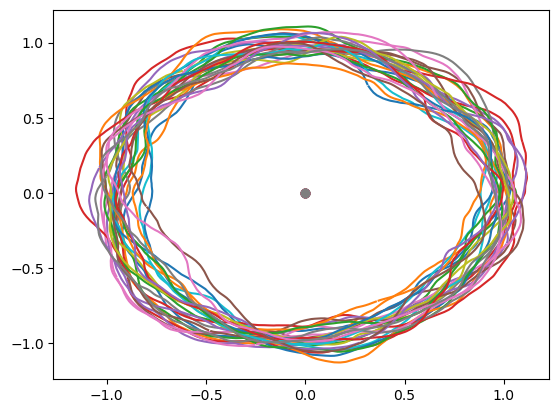

In [9]:
for section in vertices2d:
    plt.plot(*section.T)
    plt.scatter(*np.mean(section, axis = 0))


In [ ]:
# check the roughness computation on a single point. 
section = sections[5]

nP = section[5]

dist_to_plane = np.abs((mesh_data.centroids - np.mean(section[0], axis =0)) @ nP)
within_plane = dist_to_plane < 0.2
within_smaller_plane = dist_to_plane < 0.01
points_near_section = mesh_data.centroids[within_plane]
points_nearest_section_id = np.argwhere(dist_to_plane[within_plane] < 0.01).flatten()
neigh = NearestNeighbors(n_neighbors=1000, radius=0.5)
neigh.fit(points_near_section)
# at each vertex. 
# find the nearest neighbours.
distances, indices = neigh.kneighbors(points_near_section)

roughnesses = []

for thepoint_idx in points_nearest_section_id:
    thepoint, dist, idx = points_near_section[thepoint_idx], distances[thepoint_idx], indices[thepoint_idx]
    
    within_radius = idx[1:][dist[1:] < 0.18]

    X = points_near_section[within_radius]

    C = np.mean(X, axis = 0)

    # smallest eigenvector of principal component analysis. 
    rows, cols = X.shape
    # covariance matrix
    Sigma =  (X-C).T @ (X-C)
    # eigen value decomposition
    D, S = np.linalg.eig(Sigma)
    # smallest eigenvalue
    nn = S[2]

    roughnesses.append(np.abs((thepoint-C) @ nn))
the_roughness = np.quantile(roughnesses, 0.68)

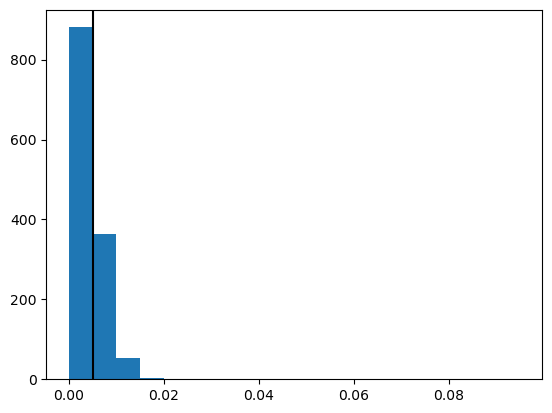

In [80]:
plt.hist(roughnesses, bins = np.arange(0, 0.1, 0.005))
plt.axvline(the_roughness, zorder = 10, color = "k")

7.0338297 5.3665295 0.07988745
planarity coeff.: 0.75160
linearity coeff.: 0.23704
1.1843421 -3.9588661


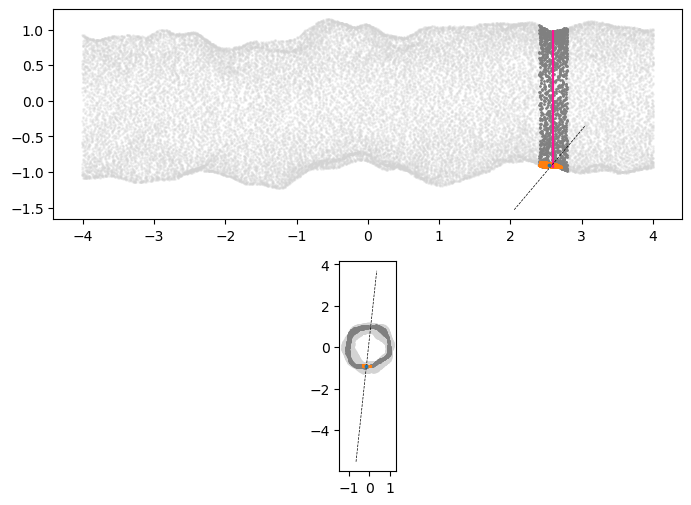

In [82]:
fig, axes = plt.subplots(2, 1, figsize=(10,6))

point = 45

ax = axes[0]
ax.plot(*section[0][:, [0, 2]].T, color = "deeppink", ls = "-")
ax.scatter(*mesh_data.centroids[::20, [0, 2]].T, color = "lightgrey", alpha = 0.25, s = 1)
ax.set_aspect("equal")

ax.scatter(*points_near_section[::20, [0, 2]].T, s = 1, color = "grey")

within_radius = indices[point][1:][distances[point][1:] < 0.18]

X = points_near_section[within_radius]
C = np.mean(X, axis = 0)

# smallest eigenvector of principal component analysis. 
rows, cols = X.shape
# covariance matrix
Sigma =  (X-C).T @ (X-C)
# eigen value decomposition
D, S = np.linalg.eig(Sigma)

# smallest eigenvalue
ax.scatter(*points_near_section[point][[0,2]], zorder = 100, s = 3)
nn = S[np.argmin(D)] 

ax.scatter(*X[::1, [0, 2]].T, s = 1)
# nn[0]*x+nn[1]y +nn[2]z+d = 0 
# planarity 
l1, l2, l3 = np.sort(D)[::-1]
print(l1, l2, l3)
print(f"planarity coeff.: {(l2-l3)/l1:.5f}")
print(f"linearity coeff.: {(l1-l2)/l1:.5f}")


d = - nn @ C
y =  points_near_section[point][1]
slope, intercept = -nn[0]/nn[2], -(nn[1]*y+d)/nn[2]
print(slope, intercept)
xi = np.linspace(-0.5+C[0], 0.5+C[0])
zi = slope*xi +intercept
ax.plot(xi, zi, color = "k", ls = "--", lw=0.5)


ax = axes[1]
ax.scatter(*mesh_data.centroids[::20, [1, 2]].T, color = "lightgrey", alpha = 0.25, s = 1)
ax.set_aspect("equal")
ax.scatter(*points_near_section[::20, [1, 2]].T, s = 1, color = "grey")
ax.scatter(*points_near_section[point][[1,2]], zorder = 100, s = 3)

ax.scatter(*X[::1, [1, 2]].T, s = 1)

x =  points_near_section[point][0]
slope, intercept = -nn[1]/nn[2], -(nn[0]*x+d)/nn[2]
yi = np.linspace(-0.5+C[1], 0.5+C[1])
zi = slope*yi +intercept
ax.plot(yi, zi, color = "k", ls = "--", lw=0.5)


In [40]:
section_roughness = []

for section, P in tqdm(zip(sections, centrespline[1:])):

    nP = section[5]
    dist_to_plane = np.abs((mesh_data.centroids - P) @ nP)
    within_plane = dist_to_plane < 0.1
    points_near_section = mesh_data.centroids[within_plane]
    neigh = NearestNeighbors(n_neighbors=1000, radius=0.25)
    neigh.fit(points_near_section)
    # at each vertex. 
    # find the nearest neighbours.
    distances, indices = neigh.kneighbors(points_near_section)

    roughnesses = []

    for thepoint, dist, idx in zip(points_near_section, distances, indices):

        within_radius = idx[1:][dist[1:] < 0.25]

        X = points_near_section[within_radius]

        C = np.mean(X, axis = 0)

        # smallest eigenvector of principal component analysis. 
        rows, cols = X.shape
        # covariance matrix
        Sigma =  (X-C).T @ (X-C)
        # eigen value decomposition
        D, S = np.linalg.eig(Sigma)
        # smallest eigen vector is the plane normal. 
        nn = S[2]

        roughnesses.append(np.abs((thepoint-C) @ nn))
    the_roughness = np.quantile(np.array(roughnesses), 0.68)

    section_roughness.append(the_roughness)

28it [01:21,  2.91s/it]


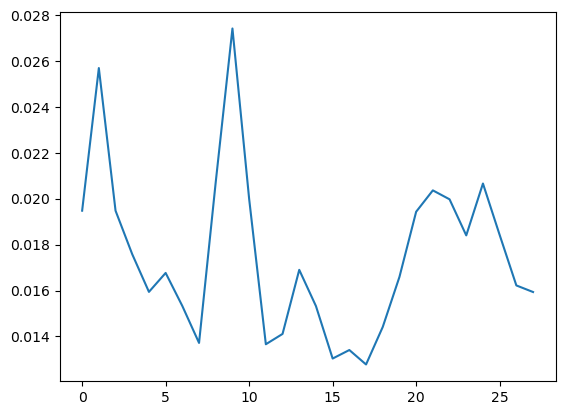

In [42]:
plt.plot(section_roughness)